# hw3: Обучение без учителя

*Спасибо ещё одному великому курсу mlcourse.ai и авторам: Ольга Дайховская (@aiho в Slack ODS), Юрий Кашницкий (@yorko в Slack ODS).*

Автор: Богданов Михаил

### О задании

В этом задании мы разберемся с тем, как работают методы снижения размерности и кластеризации данных. Заодно еще раз попрактикуемся в
задаче классификации.

Мы будем работать с набором данных [Samsung Human Activity Recognition](https://archive.ics.uci.edu/ml/datasets/Human+Activity+Recognition+Using+Smartphones). Данные поступают с акселерометров и гироскопов мобильных телефонов Samsung Galaxy S3 (подробнее про признаки – по ссылке на UCI выше), также известен вид активности человека с телефоном в кармане – ходил ли он, стоял, лежал, сидел или шел вверх/вниз по лестнице.

Вначале мы представим, что вид активности нам неизвестнен, и попробуем кластеризовать людей чисто на основе имеющихся признаков. Затем решим задачу определения вида физической активности именно как задачу классификации.

**Заполните код в клетках (где написано "Ваш код здесь") и ответьте на вопросы, выделив ответ полужирным** (``` **выделить двойными звёздочками** ```).

### Оценивание и штрафы
Вам необходимо ответить на 10 вопросов и выполнить 2 задания. Каждое из заданий и вопросов имеет определенную «стоимость» (указана в скобках). Максимально допустимая оценка за работу — 10 баллов. Неэффективная и/или неоригинальная реализация кода может негативно отразиться на оценке.

### Формат сдачи
Заполненный ноутбук ```hw3-unsupervised.ipynb``` необходимо загрузить на свой Github. Затем нужно оставить комментарий в Google-таблице с оценками в столбце "hw3" в строке со своей фамилией о том, что вы выполнили работу и оставить ссылку на ноутбук.


In [1]:
from pathlib import Path
from time import perf_counter
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn import metrics
from sklearn.cluster import AgglomerativeClustering, DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from threadpoolctl import threadpool_limits

%matplotlib inline
plt.style.use('seaborn-v0_8-darkgrid')
plt.rcParams.update({'figure.figsize': (8, 5), 'font.family': 'DejaVu Sans'})
thread_limit = threadpool_limits(limits=1)
RANDOM_STATE = 17
print(f'NumPy {np.__version__}, scikit-learn {sklearn.__version__}')

NumPy 2.5.4, scikit-learn 1.9.1


Читаем файлы UCI HAR прямо из архива, без распаковки на диск.

In [2]:
archive = Path('data/uci_har_features.zip')
if not archive.is_file():
    archive = Path('hw3') / archive

with ZipFile(archive) as z:
    with z.open('X_train.txt') as f:
        X_train = np.loadtxt(f)
    with z.open('y_train.txt') as f:
        y_train = np.loadtxt(f, dtype=int)
    with z.open('X_test.txt') as f:
        X_test = np.loadtxt(f)
    with z.open('y_test.txt') as f:
        y_test = np.loadtxt(f, dtype=int)
    with z.open('activity_labels.txt') as f:
        activity_ids = np.loadtxt(f, dtype=int, usecols=0)
    with z.open('features.txt') as f:
        feature_names = np.loadtxt(f, dtype=str, usecols=1)

assert X_train.shape == (7352, 561) and y_train.shape == (7352,)
assert X_test.shape == (2947, 561) and y_test.shape == (2947,)
assert len(feature_names) == X_train.shape[1]
print('Размеры обучающей и тестовой выборок:', X_train.shape, X_test.shape)

Размеры обучающей и тестовой выборок: (7352, 561) (2947, 561)


Для кластеризации нам не нужен вектор ответов, поэтому будем работать с объединением обучающей и тестовой выборок. Объедините *X_train* с *X_test*, а *y_train* – с *y_test*.

In [3]:
X = np.vstack([X_train, X_test])
y = np.concatenate([y_train, y_test])

Определим число уникальных значений меток целевого класса.

In [4]:
classes = np.unique(y)
n_classes = classes.size
np.testing.assert_array_equal(classes, activity_ids)
print('Метки классов:', classes)

Метки классов: [1 2 3 4 5 6]


[Эти метки соответствуют:](https://archive.ics.uci.edu/ml/machine-learning-databases/00240/UCI%20HAR%20Dataset.names)
- 1 - ходьбе
- 2 - подъему вверх по лестнице
- 3 - спуску по лестнице
- 4 - сидению
- 5 - стоянию
- 6 - лежанию

*уж простите, если звучание этих существительных кажется корявым :)*

In [5]:
activity_names = dict(zip(activity_ids, [
    'ходьба', 'подъём по лестнице', 'спуск по лестнице',
    'сидение', 'стояние', 'лежание',
]))

Отмасштабируйте выборку с помощью `StandardScaler` с параметрами по умолчанию.

In [6]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

Понижаем размерность с помощью PCA, оставляя столько компонент, сколько нужно для того, чтобы объяснить как минимум 90% дисперсии исходных (отмасштабированных) данных. Используйте отмасштабированную выборку и зафиксируйте random_state (константа RANDOM_STATE).

In [7]:
pca = PCA(n_components=0.90, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)

**Вопрос 1:** (1 балл)

Какое минимальное число главных компонент нужно выделить, чтобы объяснить 90% дисперсии исходных (отмасштабированных) данных?

**Варианты:**
- 56
- 65
- 66
- 193

In [8]:
explained = pca.explained_variance_ratio_.cumsum()
print(f'Компонент: {pca.n_components_}')
print(f'Доля дисперсии: {explained[-2]:.3%} до последней, {explained[-1]:.3%} с ней')

Компонент: 65
Доля дисперсии: 89.874% до последней, 90.048% с ней


**Ответ 1.** Оставляем **65 компонент**: с 64 набираем 89,874% дисперсии, с 65 — 90,048%.

**Вопрос 2:** (0.5 баллов)

Сколько процентов дисперсии приходится на первую главную компоненту? Округлите до целых процентов.

**Варианты:**
- 45
- 51
- 56
- 61

In [9]:
first_pc = pca.explained_variance_ratio_[0]
print(f'Первая компонента: {first_pc:.2%}, после округления: {first_pc:.0%}')

Первая компонента: 50.74%, после округления: 51%


**Ответ 2.** На первую компоненту получаем 50,74%, после округления — **51%**.

Визуализируйте данные в проекции на первые две главные компоненты.

**Вопрос 3:** (0.5 баллов)

Если все получилось правильно, Вы увидите сколько-то кластеров, почти идеально отделенных друг от друга. Какие виды активности входят в эти кластеры?

**Ответ:**
- 1 кластер: все 6 активностей
- 2 кластера: (ходьба, подъем вверх по лестнице, спуск по лестнице) и (сидение, стояние, лежание)
- 3 кластера: (ходьба), (подъем вверх по лестнице, спуск по лестнице) и (сидение, стояние, лежание)
- 6 кластеров

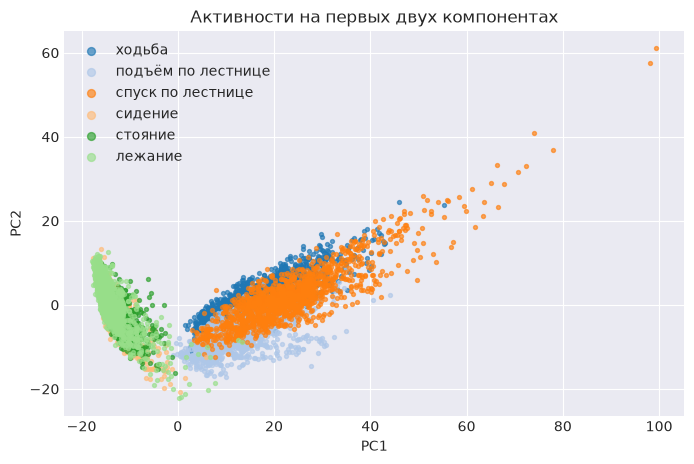

In [10]:
def plot_groups(ax, coords, labels, names, title):
    for i, label in enumerate(np.unique(labels)):
        points = coords[labels == label]
        color = '0.6' if label == -1 else plt.cm.tab20(i % 20)
        ax.scatter(points[:, 0], points[:, 1], s=8, alpha=0.65,
                   color=color, label=names.get(label, str(label)))
    ax.set_title(title)


fig, ax = plt.subplots()
plot_groups(ax, X_pca[:, :2], y, activity_names, 'Активности на первых двух компонентах')
ax.set(xlabel='PC1', ylabel='PC2')
ax.legend(markerscale=2)
plt.show()

**Ответ 3.** На графике видим **две группы**. В одной ходьба и движение по лестнице, в другой сидение, стояние и лежание. Внутри групп не видим такого же чёткого разделения.

------------------------------

**Задание 1.** (1 балл)

Сделайте кластеризацию данных методом `KMeans` (собственная имплементация и готовая реализация), обучив модель на данных со сниженной за счет PCA размерностью. В данном случае мы подскажем, что нужно искать именно 6 кластеров, но в общем случае мы не будем знать, сколько кластеров надо искать.

Параметры:

- **n_clusters** = n_classes (число уникальных меток целевого класса)
- **n_init** = 100
- **random_state** = RANDOM_STATE (для воспроизводимости результата)

Остальные параметры со значениями по умолчанию.

Для своего K-means используем `k-means++`, затем повторяем два шага: относим точки к ближайшим центрам и пересчитываем средние. Из 100 запусков берём тот, где сумма квадратов расстояний до центров меньше всего. Квадраты расстояний считаем через нормы и скалярное произведение, чтобы не хранить все разности в памяти.

In [11]:
def squared_distances(X, centers, x_norm2):
    distances = X @ centers.T
    distances *= -2
    distances += x_norm2[:, None]
    distances += np.einsum('ij,ij->i', centers, centers)
    return np.maximum(distances, 0, out=distances)


class MyKMeans:
    def __init__(self, n_clusters=8, *, n_init=10, max_iter=300, tol=1e-4,
                 random_state=None):
        self.n_clusters = n_clusters
        self.n_init = n_init
        self.max_iter = max_iter
        self.tol = tol
        self.random_state = random_state

    def _init_centers(self, X, x_norm2, rng):
        k = self.n_clusters
        centers = np.empty((k, X.shape[1]))
        centers[0] = X[rng.randint(len(X))]
        closest = squared_distances(X, centers[:1], x_norm2)[:, 0]
        n_candidates = 2 + int(np.log(k))
        for i in range(1, k):
            weights = closest.cumsum()
            if weights[-1] == 0:
                centers[i:] = centers[0]
                break
            draws = rng.uniform(0, weights[-1], size=n_candidates)
            ids = np.searchsorted(weights, draws, side='right').clip(max=len(X) - 1)
            distances = squared_distances(X, X[ids], x_norm2)
            np.minimum(distances, closest[:, None], out=distances)
            best = distances.sum(axis=0).argmin()
            centers[i] = X[ids[best]]
            closest = distances[:, best]
        return centers

    def _lloyd(self, X, x_norm2, centers, tolerance):
        k = self.n_clusters
        rows = np.arange(len(X))
        cluster_ids = np.arange(k)
        previous = None
        for step in range(1, self.max_iter + 1):
            distances = squared_distances(X, centers, x_norm2)
            labels = distances.argmin(axis=1)
            counts = np.bincount(labels, minlength=k)
            sums = (cluster_ids[:, None] == labels).astype(X.dtype) @ X

            empty = np.flatnonzero(counts == 0)
            if empty.size:
                nearest = distances[rows, labels]
                farthest = iter(np.argsort(-nearest))
                for cluster in empty:
                    for obj in farthest:
                        old = labels[obj]
                        if counts[old] > 1:
                            sums[old] -= X[obj]
                            counts[old] -= 1
                            sums[cluster] = X[obj]
                            counts[cluster] = 1
                            break

            new_centers = sums / counts[:, None]
            shift = np.square(new_centers - centers).sum()
            centers = new_centers
            if np.array_equal(labels, previous) or shift <= tolerance:
                break
            previous = labels

        distances = squared_distances(X, centers, x_norm2)
        labels = distances.argmin(axis=1)
        return distances[rows, labels].sum(), centers, labels, step

    def fit(self, X):
        X = np.asarray(X, dtype=np.float64)
        if X.ndim != 2 or not 1 <= self.n_clusters <= len(X):
            raise ValueError('Нужно от 1 до n_samples кластеров для двумерного X')
        if self.n_init < 1 or self.max_iter < 1 or self.tol < 0:
            raise ValueError('Нужны положительные n_init, max_iter и неотрицательный tol')

        offset = X.mean(axis=0)
        X = X - offset
        x_norm2 = np.einsum('ij,ij->i', X, X)
        tolerance = self.tol * x_norm2.mean() / X.shape[1]
        rng = np.random.RandomState(self.random_state)
        self.inertia_ = np.inf
        for _ in range(self.n_init):
            centers = self._init_centers(X, x_norm2, rng)
            inertia, centers, labels, steps = self._lloyd(X, x_norm2, centers, tolerance)
            if inertia < self.inertia_:
                self.inertia_ = inertia
                self.cluster_centers_ = centers + offset
                self.labels_ = labels
                self.n_iter_ = steps
        return self

In [12]:
examples = np.array([[0., 0.], [0., 2.], [9., 0.], [9., 2.]])
toy = MyKMeans(n_clusters=2, n_init=5, random_state=RANDOM_STATE).fit(examples)
np.testing.assert_allclose(toy.inertia_, 4.)
np.testing.assert_allclose(toy.cluster_centers_[toy.cluster_centers_[:, 0].argsort()],
                           [[0., 1.], [9., 1.]])
duplicate_toy = MyKMeans(n_clusters=3, random_state=RANDOM_STATE).fit(np.ones((4, 2)))
np.testing.assert_allclose(duplicate_toy.inertia_, 0.)

km_params = {'n_init': 100, 'random_state': RANDOM_STATE}
km_own = MyKMeans(n_clusters=n_classes, **km_params).fit(X_pca)
km_sklearn = KMeans(n_clusters=n_classes, **km_params).fit(X_pca)
cluster_labels = km_sklearn.labels_
residual = X_pca - km_own.cluster_centers_[km_own.labels_]
np.testing.assert_allclose(km_own.inertia_, np.square(residual).sum())
print(f'Инерция: своя — {km_own.inertia_:,.1f}; sklearn — {km_sklearn.inertia_:,.1f}')

Инерция: своя — 2,003,454.9; sklearn — 2,003,454.9


Визуализируйте данные в проекции на первые две главные компоненты. Раскрасьте точки в соответствии с полученными метками кластеров.

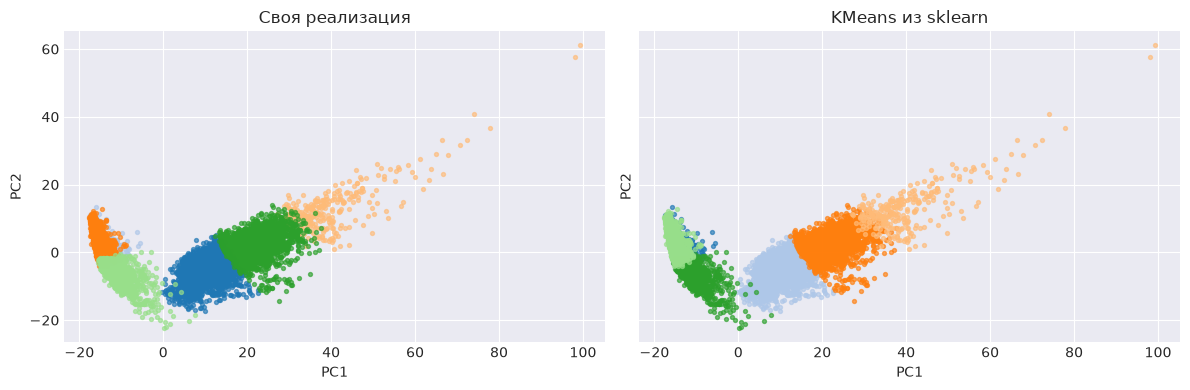

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True, sharey=True)
for ax, labels, title in zip(axes, [km_own.labels_, cluster_labels],
                             ['Своя реализация', 'KMeans из sklearn']):
    plot_groups(ax, X_pca[:, :2], labels, {}, title)
    ax.set(xlabel='PC1', ylabel='PC2')
plt.tight_layout()
plt.show()

Посмотрите на соответствие между метками кластеров и исходными метками классов и на то, какие виды активностей алгоритм `KMeans` путает.

In [14]:
def cluster_table(labels):
    return pd.crosstab(y, labels + 1, margins=True, margins_name='все').rename(
        index=activity_names).rename_axis(index='Активность', columns='Кластер')


tab_own = cluster_table(km_own.labels_)
tab = cluster_table(cluster_labels)
print('Своя реализация')
display(tab_own)
print('KMeans из sklearn')
display(tab)

Своя реализация


Кластер,1,2,3,4,5,6,все
Активность,,,,,,,
ходьба,903,0,0,78,741,0,1722
подъём по лестнице,1241,0,0,5,296,2,1544
спуск по лестнице,320,0,0,196,890,0,1406
сидение,1,1235,91,0,0,450,1777
стояние,0,1344,0,0,0,562,1906
лежание,5,52,1558,0,0,329,1944
все,2470,2631,1649,279,1927,1343,10299


KMeans из sklearn


Кластер,1,2,3,4,5,6,все
Активность,,,,,,,
ходьба,0,903,741,78,0,0,1722
подъём по лестнице,0,1241,296,5,2,0,1544
спуск по лестнице,0,320,890,196,0,0,1406
сидение,1235,1,0,0,450,91,1777
стояние,1344,0,0,0,562,0,1906
лежание,52,5,0,0,329,1558,1944
все,2631,2470,1927,279,1343,1649,10299


Видим, что каждому классу (т.е. каждой активности) соответствуют несколько кластеров. Давайте посмотрим на максимальную долю объектов в классе, отнесенных к какому-то одному кластеру. Это будет простой метрикой, характеризующей, насколько легко класс отделяется от других при кластеризации.

Пример: если для класса "спуск по лестнице", в котором 1406 объектов,  распределение кластеров такое:
 - кластер 1 – 900
 - кластер 3 – 500
 - кластер 6 – 6,

то такая доля будет 900 / 1406 $\approx$ 0.64.


**Вопрос 4:** (1 балл)

Какой вид активности отделился от остальных лучше всего в терминах простой  метрики, описанной выше?

**Ответ:**
- ходьба
- стояние
- спуск по лестнице
- перечисленные варианты не подходят

In [15]:
def max_cluster_share(table):
    return table.iloc[:-1, :-1].max(axis=1) / table['все'].iloc[:-1]


shares = pd.DataFrame({'Свой KMeans': max_cluster_share(tab_own),
                       'KMeans sklearn': max_cluster_share(tab)})
display(shares.style.format('{:.2%}'))

,Свой KMeans,KMeans sklearn
Активность,,
ходьба,52.44%,52.44%
подъём по лестнице,80.38%,80.38%
спуск по лестнице,63.30%,63.30%
сидение,69.50%,69.50%
стояние,70.51%,70.51%
лежание,80.14%,80.14%


**Ответ 4.** Выбираем **«перечисленные варианты не подходят»**. Для подъёма по лестнице находим наибольшую долю: 1241 из 1544 объектов (80,38%) в одном кластере. Для лежания получаем чуть меньше — 80,14%.

Видно, что kMeans не очень хорошо отличает только активности друг от друга. Используйте метод локтя, чтобы выбрать оптимальное количество кластеров. Параметры алгоритма и данные используем те же, что раньше, меняем только `n_clusters`.

**Вопрос 5:** (1 балл)

Какое количество кластеров оптимально выбрать, согласно методу локтя?

**Ответ:**
- 1
- 2
- 3
- 4

,Свой KMeans,KMeans sklearn
Число кластеров,,
1,5202757.7,5202757.7
2,2697926.8,2697926.8
3,2346425.1,2346425.1
4,2207131.8,2207131.8
5,2080985.2,2080985.1
6,2003454.9,2003454.9


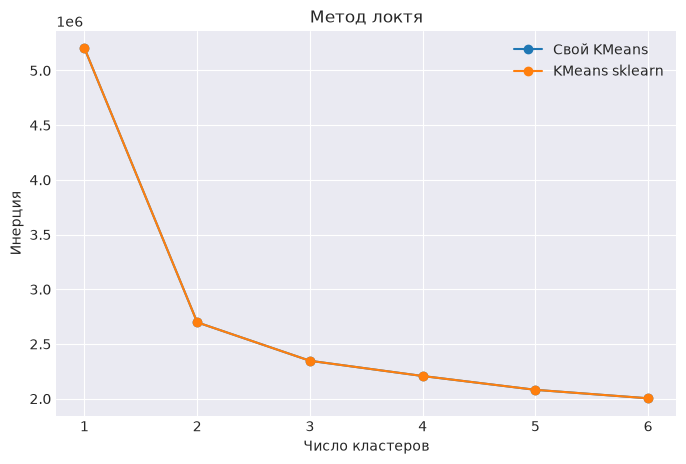

In [16]:
ks = np.arange(1, n_classes + 1)
inertia = pd.DataFrame(
    {
        name: [
            (model_at_six if k == n_classes else cls(n_clusters=k, **km_params).fit(X_pca)).inertia_
            for k in ks
        ]
        for cls, name, model_at_six in [
            (MyKMeans, 'Свой KMeans', km_own),
            (KMeans, 'KMeans sklearn', km_sklearn),
        ]
    }, index=pd.Index(ks, name='Число кластеров'),
)
display(inertia.round(1))
ax = inertia.plot(marker='o', xticks=ks)
ax.set(ylabel='Инерция', title='Метод локтя')
plt.show()

**Ответ 5.** По графику выбираем **2 кластера**. При переходе от одного к двум видим снижение инерции примерно на 2,50 млн, от двух к трём — только на 0,35 млн.

------------------------

Попробуем еще один метод кластеризации, который описывался в статье – агломеративную кластеризацию.

Посчитайте Adjusted Rand Index (`sklearn.metrics`) для получившегося разбиения на кластеры и для `KMeans` с параметрами из задания к 4 вопросу.

**Вопрос 6:** (1 балл)

Отметьте все верные утверждения.

**Варианты:**
- Согласно ARI, KMeans справился с кластеризацией хуже, чем Agglomerative Clustering
- Для ARI не имеет значения какие именно метки присвоены кластерам, имеет значение только разбиение объектов на кластеры
- В случае случайного разбиения на кластеры ARI будет близок к нулю

In [17]:
ag = AgglomerativeClustering(n_clusters=n_classes, linkage='ward').fit(X_pca)
ari = metrics.adjusted_rand_score
random_labels = np.random.default_rng(RANDOM_STATE).permutation(cluster_labels)
ari_scores = pd.Series({
    'Свой KMeans': ari(y, km_own.labels_),
    'KMeans sklearn': ari(y, cluster_labels),
    'Агломеративная (Ward)': ari(y, ag.labels_),
    'KMeans sklearn с переименованными кластерами': ari(y, (cluster_labels + 1) % n_classes),
    'Случайное разбиение с теми же размерами кластеров': ari(y, random_labels),
}, name='ARI')
display(ari_scores.round(5))

Свой KMeans                                          0.41981
KMeans sklearn                                       0.41981
Агломеративная (Ward)                                0.49363
KMeans sklearn с переименованными кластерами         0.41981
Случайное разбиение с теми же размерами кластеров    0.00013
Name: ARI, dtype: float64

**Ответ 6.** Выбираем **все три утверждения**. Получаем ARI 0,41981 у K-means и 0,49363 у Ward. Если меняем номера кластеров, получаем тот же ARI; если случайно переставляем метки по объектам — 0,00013.

-------------------------------

Можно заметить, что задача не очень хорошо решается именно как задача кластеризации, если выделять несколько кластеров (> 2). Давайте теперь решим задачу классификации, вспомнив, что данные у нас размечены.  

Для классификации используйте метод опорных векторов – класс `sklearn.svm.LinearSVC`. Мы в курсе отдельно не рассматривали этот алгоритм, но он очень известен, почитать про него можно, например, в материалах Евгения Соколова –  [тут](https://github.com/esokolov/ml-course-msu/blob/master/ML16/lecture-notes/Sem11_linear.pdf).

Настройте для `LinearSVC` гиперпараметр `C` с помощью `GridSearchCV`.

- Обучите новый `StandardScaler` на обучающей выборке (со всеми исходными признаками), прмиените масштабирование к тестовой выборке
- В `GridSearchCV` укажите  cv=3.

In [18]:
train_scaler = StandardScaler()
X_train_scaled = train_scaler.fit_transform(X_train)
X_test_scaled = train_scaler.transform(X_test)

**Вопрос 7** (0.5 баллов)

Какое значение гиперпараметра `C` было выбрано лучшим по итогам кросс-валидации?

**Ответ:**
- 0.001
- 0.01
- 0.1
- 1
- 10

In [19]:
svc_params = {'C': [0.001, 0.01, 0.1, 1, 10]}


def fit_svc_grid(features):
    grid = GridSearchCV(LinearSVC(random_state=RANDOM_STATE), svc_params,
                        cv=3, scoring='accuracy', n_jobs=1)
    start = perf_counter()
    grid.fit(features, y_train)
    seconds = perf_counter() - start
    return grid, seconds


def cv_scores(grid):
    return pd.Series(grid.cv_results_['mean_test_score'],
                     index=pd.Index(svc_params['C'], name='C'), name='Accuracy CV')


best_svc, seconds_full = fit_svc_grid(X_train_scaled)
display(cv_scores(best_svc).map('{:.2%}'.format))
print(f'Лучший C: {best_svc.best_params_["C"]}; accuracy CV: {best_svc.best_score_:.2%}')

/home/bogdanoff/study/university/ml/venv/lib/python3.12/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


/home/bogdanoff/study/university/ml/venv/lib/python3.12/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


/home/bogdanoff/study/university/ml/venv/lib/python3.12/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


C
0.001     92.55%
0.010     93.59%
0.100     93.81%
1.000     93.08%
10.000    92.25%
Name: Accuracy CV, dtype: str

Лучший C: 0.1; accuracy CV: 93.81%


**Ответ 7.** Выбираем **C = 0,1**: на трёх фолдах получаем 93,81%. При больших `C` видим предупреждения о сходимости. Оставляем настройки `LinearSVC` из задания и приводим результаты этого запуска.

**Вопрос 8:** (0.5 балл)

Какой вид активности SVM определяет хуже всего в терминах точности? Полноты? 

**Ответ:**
- по точности – подъем вверх по лестнице, по полноте – лежание
- по точности – лежание, по полноте – сидение
- по точности – ходьба, по полноте – ходьба
- по точности – сидение, по полноте – стояние

In [20]:
y_predicted = best_svc.predict(X_test_scaled)
confusion = pd.crosstab(y_test, y_predicted, margins=True, margins_name='все')
display(confusion.rename(index=activity_names, columns=activity_names)
        .rename_axis(index='Истинный класс', columns='Предсказанный класс'))

precision, recall, _, _ = metrics.precision_recall_fscore_support(
    y_test, y_predicted, labels=classes, zero_division=0)
svc_scores = pd.DataFrame({'Precision': precision, 'Recall': recall},
                          index=[activity_names[label] for label in classes])
display(svc_scores.style.format('{:.2%}'))
print('Минимумы:', svc_scores.idxmin().to_dict())
print(f'Accuracy на тесте: {metrics.accuracy_score(y_test, y_predicted):.2%}')

Предсказанный класс,ходьба,подъём по лестнице,спуск по лестнице,сидение,стояние,лежание,все
Истинный класс,,,,,,,
ходьба,494,2,0,0,0,0,496
подъём по лестнице,12,459,0,0,0,0,471
спуск по лестнице,2,4,413,1,0,0,420
сидение,0,4,0,426,61,0,491
стояние,0,0,0,15,517,0,532
лежание,0,0,0,0,11,526,537
все,508,469,413,442,589,526,2947


,Precision,Recall
ходьба,97.24%,99.60%
подъём по лестнице,97.87%,97.45%
спуск по лестнице,100.00%,98.33%
сидение,96.38%,86.76%
стояние,87.78%,97.18%
лежание,100.00%,97.95%


Минимумы: {'Precision': 'стояние', 'Recall': 'сидение'}
Accuracy на тесте: 96.20%


**Ответ 8.** В списке не находим точной пары. По столбцам матрицы ошибок считаем precision: минимум у стояния, 517 из 589 (87,78%). По строкам считаем recall: минимум у сидения, 426 из 491 (86,76%).

Наконец, проделайте то же самое, что в 7 вопросе, только добавив PCA.

- Используйте выборки `X_train_scaled` и `X_test_scaled`
- Обучите тот же PCA, что раньше, на отмасшабированной обучающей выборке, примените преобразование к тестовой
- Настройте гиперпараметр `C` на кросс-валидации по обучающей выборке с PCA-преобразованием. Вы заметите, насколько это проходит быстрее, чем раньше.

**Вопрос 9:** (1 балл)

Какова разность между лучшим качеством (долей верных ответов) на кросс-валидации в случае всех 561 исходных признаков и во втором случае, когда применялся метод главных компонент? Округлите до целых процентов.

**Варианты:**
- Качество одинаковое
- 2%
- 4%
- 10%
- 20%


In [21]:
train_pca = PCA(n_components=0.90, random_state=RANDOM_STATE)
X_train_pca = train_pca.fit_transform(X_train_scaled)
X_test_pca = train_pca.transform(X_test_scaled)
best_svc_pca, seconds_pca = fit_svc_grid(X_train_pca)
cv_comparison = pd.concat([cv_scores(best_svc), cv_scores(best_svc_pca)], axis=1)
cv_comparison.columns = ['Все признаки', 'После PCA']
display(cv_comparison.style.format('{:.2%}'))

cv_drop = (best_svc.best_score_ - best_svc_pca.best_score_) * 100
y_predicted_pca = best_svc_pca.predict(X_test_pca)
print(f'Признаков после PCA: {train_pca.n_components_}; лучший C: {best_svc_pca.best_params_["C"]}')
print(f'Разность лучших accuracy CV: {cv_drop:.2f} п. п. (округлённо: {cv_drop:.0f} п. п.)')
print(f'Время GridSearchCV с переобучением: {seconds_full:.2f} с без PCA, {seconds_pca:.2f} с с PCA')
print(f'Accuracy после PCA на тесте: {metrics.accuracy_score(y_test, y_predicted_pca):.2%}')

,Все признаки,После PCA
C,,
0.001000,92.55%,88.07%
0.010000,93.59%,88.78%
0.100000,93.81%,89.84%
1.000000,93.08%,89.55%
10.000000,92.25%,89.30%


Признаков после PCA: 63; лучший C: 0.1
Разность лучших accuracy CV: 3.97 п. п. (округлённо: 4 п. п.)
Время GridSearchCV с переобучением: 45.99 с без PCA, 1.79 с с PCA
Accuracy после PCA на тесте: 91.92%


**Ответ 9.** После PCA получаем примерно 89,84% вместо 93,81%. Разность 3,97 п. п. округляем до **4 процентных пунктов**.

**Вопрос 10:** (1 балл)

Выберите все верные утверждения:

**Варианты:**
- Метод главных компонент в данном случае позволил уменьшить время обучения модели, при этом качество (доля верных ответов на кросс-валидации) очень пострадало, более чем на 10%
- PCA можно использовать для визуализации данных, однако для этой задачи есть и лучше подходящие методы, например, tSNE. Зато PCA имеет меньшую вычислительную сложность
- PCA строит линейные комбинации исходных признаков, и в некоторых задачах они могут плохо интерпретироваться человеком

**Ответ 10.** Выбираем **второе и третье утверждения**. После PCA быстрее подбираем `C`, но теряем около 4 п. п., не больше 10. В PCA получаем линейные комбинации исходных полей, и их не всегда легко объяснить. Для двумерной визуализации можем взять t-SNE, но потратим больше времени на расчёт.

**Задание 2.** (1 балл)

Попробуйте использовать DBSCAN в качестве алгоритма кластеризации и метод понижения размерности tSNE.

Строим t-SNE в двух измерениях по результату PCA и запускаем DBSCAN на проекции. Берём `min_samples=15`, а `eps` выбираем по 90-му процентилю расстояний до 15-го соседа, считая саму точку. Метки активностей при выборе не используем.

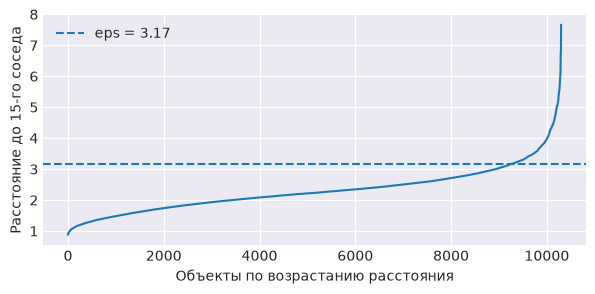

In [22]:
X_tsne = TSNE(n_components=2, perplexity=30, init='pca', learning_rate='auto',
              max_iter=1000, random_state=RANDOM_STATE, n_jobs=1).fit_transform(X_pca)

min_samples = 15
neighbors = NearestNeighbors(n_neighbors=min_samples, n_jobs=1).fit(X_tsne)
kth_dist = neighbors.kneighbors(X_tsne, return_distance=True)[0][:, -1]
eps = float(np.quantile(kth_dist, 0.90))
db_labels = DBSCAN(eps=eps, min_samples=min_samples, n_jobs=1).fit_predict(X_tsne)

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(np.sort(kth_dist))
ax.axhline(eps, linestyle='--', label=f'eps = {eps:.2f}')
ax.set(xlabel='Объекты по возрастанию расстояния', ylabel='Расстояние до 15-го соседа')
ax.legend()
plt.show()

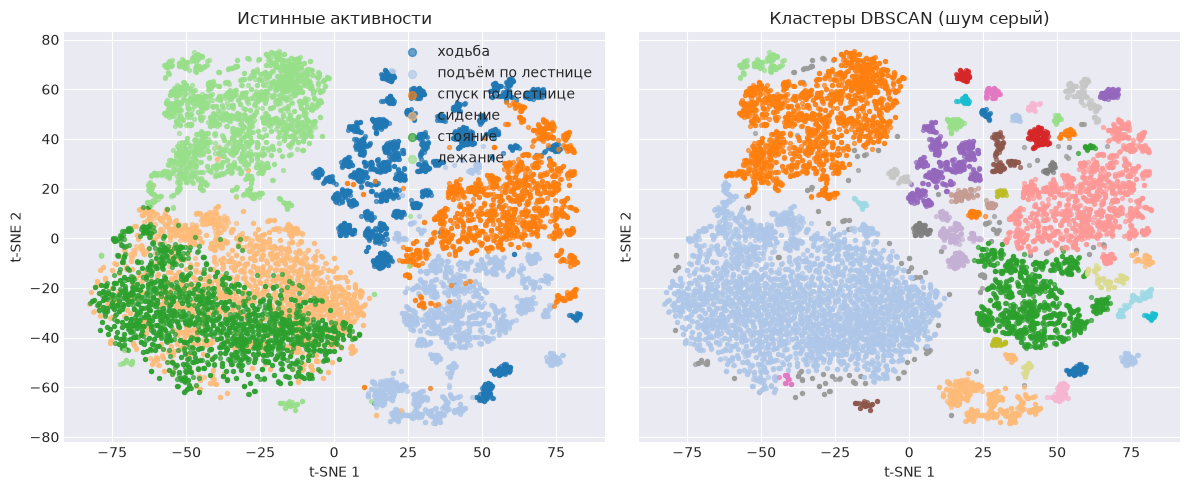

Кластеров: 45; шум: 2.35%; ARI с учётом шума: 0.5621


In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
plot_groups(axes[0], X_tsne, y, activity_names, 'Истинные активности')
axes[0].legend(markerscale=2)
plot_groups(axes[1], X_tsne, db_labels, {-1: 'шум'}, 'Кластеры DBSCAN (шум серый)')
for ax in axes:
    ax.set(xlabel='t-SNE 1', ylabel='t-SNE 2')
plt.tight_layout()
plt.show()

n_db_clusters = len(set(db_labels) - {-1})
noise_share = np.mean(db_labels == -1)
db_ari = ari(y, db_labels)
print(f'Кластеров: {n_db_clusters}; шум: {noise_share:.2%}; ARI с учётом шума: {db_ari:.4f}')

**Вывод по заданию 2.** Получаем 45 кластеров и 2,35% шума. ARI равен 0,5621 — выше, чем у K-means и Ward в нашем сравнении. При этом шесть видов активности не восстановили: на проекции разбили их на более мелкие группы.